# Paris Air Quality Forecasting

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nicotranfr/air-polluants-in-paris/blob/main/notebooks/main.ipynb)

Forecast hourly NO2, CO, O3, PM10 and PM2.5 in Paris over the next 504 hours (3 weeks).
Compare simple baselines, a zero-shot foundation model (Chronos-2) and an LSTM. Full brief: [`docs/assignment.md`](../docs/assignment.md).

## 0. Setup

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q chronos-forecasting holidays kagglehub

import kagglehub

# Kaggle auth: local -> ~/.kaggle/access_token ; Colab -> secret "KAGGLE_API_TOKEN" (read automatically)
DATA = Path(kagglehub.competition_download("x-hec-ts-2025-predicting-air-quality-in-paris"))
OUT_DIR = Path("/content") if IN_COLAB else Path("../submissions")
print(DATA, sorted(p.name for p in DATA.glob("*.csv")))

/Users/enfants/.cache/kagglehub/competitions/x-hec-ts-2025-predicting-air-quality-in-paris ['sample_submission.csv', 'test.csv', 'train.csv']


In [2]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

HORIZON = 504  # 3 weeks of hourly forecasts
SEED = 42
TIME_COL = "id"
POLLUTANTS = ["valeur_NO2", "valeur_CO", "valeur_O3", "valeur_PM10", "valeur_PM25"]

np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 4)
print("python", platform.python_version(), "| torch", torch.__version__, "| device", DEVICE)

python 3.12.1 | torch 2.14.1 | device mps


### Helpers (evaluation, plotting, submission)

- `mae_per_pollutant(y_pred)`: MAE on the validation set for each pollutant + average. Hours where the observation is missing are ignored.
- `record(name, y_pred)`: store a model's scores; `results_table()` shows all models.
- `plot_forecast(preds, pollutant)`: last 2 weeks of history, observed validation and predictions.
- `make_submission(y_pred_test)` / `check_submission(path)`: write the Kaggle CSV and validate its format.

Predictions are DataFrames indexed by timestamp with the 5 pollutant columns.

In [3]:
RESULTS = {}


def mae_per_pollutant(y_pred: pd.DataFrame, y_true: pd.DataFrame | None = None) -> pd.Series:
    y_true = val if y_true is None else y_true
    y_pred = y_pred.reindex(y_true.index)[POLLUTANTS]
    assert not y_pred.isna().any().any(), "missing predictions for some validation timestamps"
    mae = (y_true[POLLUTANTS] - y_pred).abs().mean()  # NaN observations are skipped
    mae["average"] = mae.mean()
    return mae


def record(name: str, y_pred: pd.DataFrame) -> pd.Series:
    RESULTS[name] = mae_per_pollutant(y_pred)
    return RESULTS[name]


def results_table() -> pd.DataFrame:
    if not RESULTS:
        return pd.DataFrame(columns=[*POLLUTANTS, "average"])
    return pd.DataFrame(RESULTS).T.sort_values("average")


def plot_forecast(preds: dict[str, pd.DataFrame], pollutant: str, history_hours: int = 336):
    fig, ax = plt.subplots()
    train_df[pollutant].iloc[-history_hours:].plot(ax=ax, color="grey", label="history")
    val[pollutant].plot(ax=ax, color="black", label="observed")
    for name, p in preds.items():
        p[pollutant].plot(ax=ax, label=name, alpha=0.8)
    ax.axvline(val.index[0], ls="--", c="k", lw=1)
    ax.set_title(pollutant)
    ax.legend()
    return ax


def make_submission(y_pred_test: pd.DataFrame, name: str = "submission.csv") -> Path:
    sub = y_pred_test.reindex(test["timestamp"])[POLLUTANTS].reset_index(drop=True)
    sub.insert(0, "id", test[TIME_COL].values)
    path = OUT_DIR / name
    path.parent.mkdir(parents=True, exist_ok=True)
    sub.to_csv(path, index=False)
    return path


def check_submission(path: Path) -> None:
    sub = pd.read_csv(path)
    assert list(sub.columns) == list(sample_sub.columns), f"columns {list(sub.columns)}"
    assert len(sub) == len(sample_sub), f"{len(sub)} rows, expected {len(sample_sub)}"
    assert (sub["id"] == sample_sub["id"]).all(), "ids differ from sample_submission (order or values)"
    assert not sub[POLLUTANTS].isna().any().any(), "NaN predictions"
    print(f"OK: {path} ({len(sub)} rows, {len(POLLUTANTS)} pollutants)")

# 1. Data understanding and preparation

Start by understanding the dataset before choosing a model.

**Work to complete:** Load the train and test files. Identify the timestamp column and the five pollutant columns. Check that dates are sorted and that there are no unexpected duplicates.

In [18]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
sample_sub = pd.read_csv(DATA / "sample_submission.csv")

# The timestamp is the "id" column, formatted "YYYY-MM-DD HH"
for d in (train, test):
    d["timestamp"] = pd.to_datetime(d[TIME_COL], format="%Y-%m-%d %H")
df = train.set_index("timestamp")[POLLUTANTS]

print("train:", train.shape, "| test:", test.shape)
print("columns:", list(train.columns))
print("sorted:", df.index.is_monotonic_increasing,
      "| duplicated timestamps:", df.index.duplicated().sum(),
      "| fully duplicated rows:", train.duplicated().sum())
print("test starts 1h after train ends:", test["timestamp"].iloc[0] == df.index[-1] + pd.Timedelta(hours=1))
display(df.head(), test.head())

train: (40991, 7) | test: (504, 2)
columns: ['id', 'valeur_NO2', 'valeur_CO', 'valeur_O3', 'valeur_PM10', 'valeur_PM25', 'timestamp']
sorted: True | duplicated timestamps: 0 | fully duplicated rows: 0
test starts 1h after train ends: True


,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
timestamp,,,,,
2020-01-01 00:00:00,42.9,0.718,15.7,73.1,64.4
2020-01-01 01:00:00,33.6,0.587,10.1,74.8,66.0
2020-01-01 02:00:00,29.3,NaN,5.1,51.0,44.9
2020-01-01 03:00:00,30.5,0.246,7.2,27.7,25.1
2020-01-01 04:00:00,29.3,0.204,8.3,15.3,13.6


,id,timestamp
0,2024-09-03 23,2024-09-03 23:00:00
1,2024-09-04 00,2024-09-04 00:00:00
2,2024-09-04 01,2024-09-04 01:00:00
3,2024-09-04 02,2024-09-04 02:00:00
4,2024-09-04 03,2024-09-04 03:00:00


**Points to discuss:** Why is this a time-series forecasting problem, not a standard regression problem?

> *Because the x axis are dates and order matters.*

**Points to discuss:** Why would a random train-test split create a misleading evaluation?

> *Your answer*

**Work to complete:** Check data quality: time range, missing values, duplicates, outliers and simple statistics for each pollutant.

In [5]:
full_grid = pd.date_range(df.index.min(), df.index.max(), freq="h")
print(f"time range: {df.index.min()} -> {df.index.max()}")
print(f"{len(df)} rows | {len(full_grid)} expected hourly steps | {len(full_grid.difference(df.index))} missing timestamps")

q1, q3 = df.quantile(0.25), df.quantile(0.75)
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "negative": (df < 0).sum(),
    "zero": (df == 0).sum(),
    "> Q3 + 3·IQR": (df > q3 + 3 * (q3 - q1)).sum(),
})
display(quality, df.describe().T.round(2))

time range: 2020-01-01 00:00:00 -> 2024-09-03 22:00:00
40991 rows | 40991 expected hourly steps | 0 missing timestamps


,missing,missing_%,negative,zero,> Q3 + 3·IQR
valeur_NO2,3297,8.0,0,0,190
valeur_CO,12529,30.6,0,0,581
valeur_O3,693,1.7,10,84,12
valeur_PM10,7167,17.5,0,0,330
valeur_PM25,1791,4.4,0,9,641


,count,mean,std,min,25%,50%,75%,max
valeur_NO2,37694.0,21.83,14.66,1.10,11.30,17.60,28.20,131.00
valeur_CO,28462.0,0.20,0.10,0.04,0.14,0.18,0.23,4.31
valeur_O3,40298.0,50.57,26.49,-1.90,33.00,50.70,66.60,193.10
valeur_PM10,33824.0,18.22,11.28,0.50,10.70,15.60,22.90,128.50
valeur_PM25,39200.0,11.05,8.15,0.00,5.80,8.70,13.60,111.10


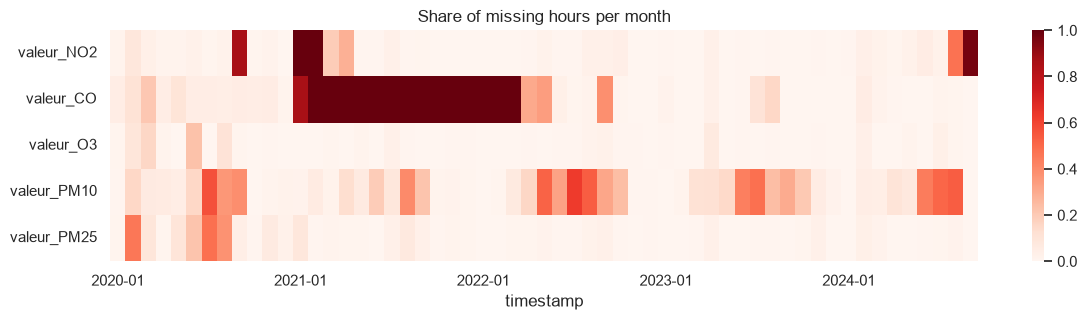

longest missing gap (hours): {'valeur_NO2': np.int64(1500), 'valeur_CO': np.int64(10949), 'valeur_O3': np.int64(131), 'valeur_PM10': np.int64(90), 'valeur_PM25': np.int64(493)}


In [6]:
# Where are the missing values? Share of missing hours per month
fig, ax = plt.subplots(figsize=(14, 3))
sns.heatmap(df.isna().resample("MS").mean().T, cmap="Reds", vmin=0, vmax=1, ax=ax,
            xticklabels=[d.strftime("%Y-%m") if d.month == 1 else "" for d in df.resample("MS").size().index])
ax.set_title("Share of missing hours per month")
plt.show()

# Longest run of consecutive missing hours per pollutant
runs = {c: df[c].isna().groupby(df[c].notna().cumsum()).sum().max() for c in POLLUTANTS}
print("longest missing gap (hours):", runs)

**Work to complete:** Plot the pollutant series and describe visible trends, daily or weekly patterns, peaks and relationships between pollutants.

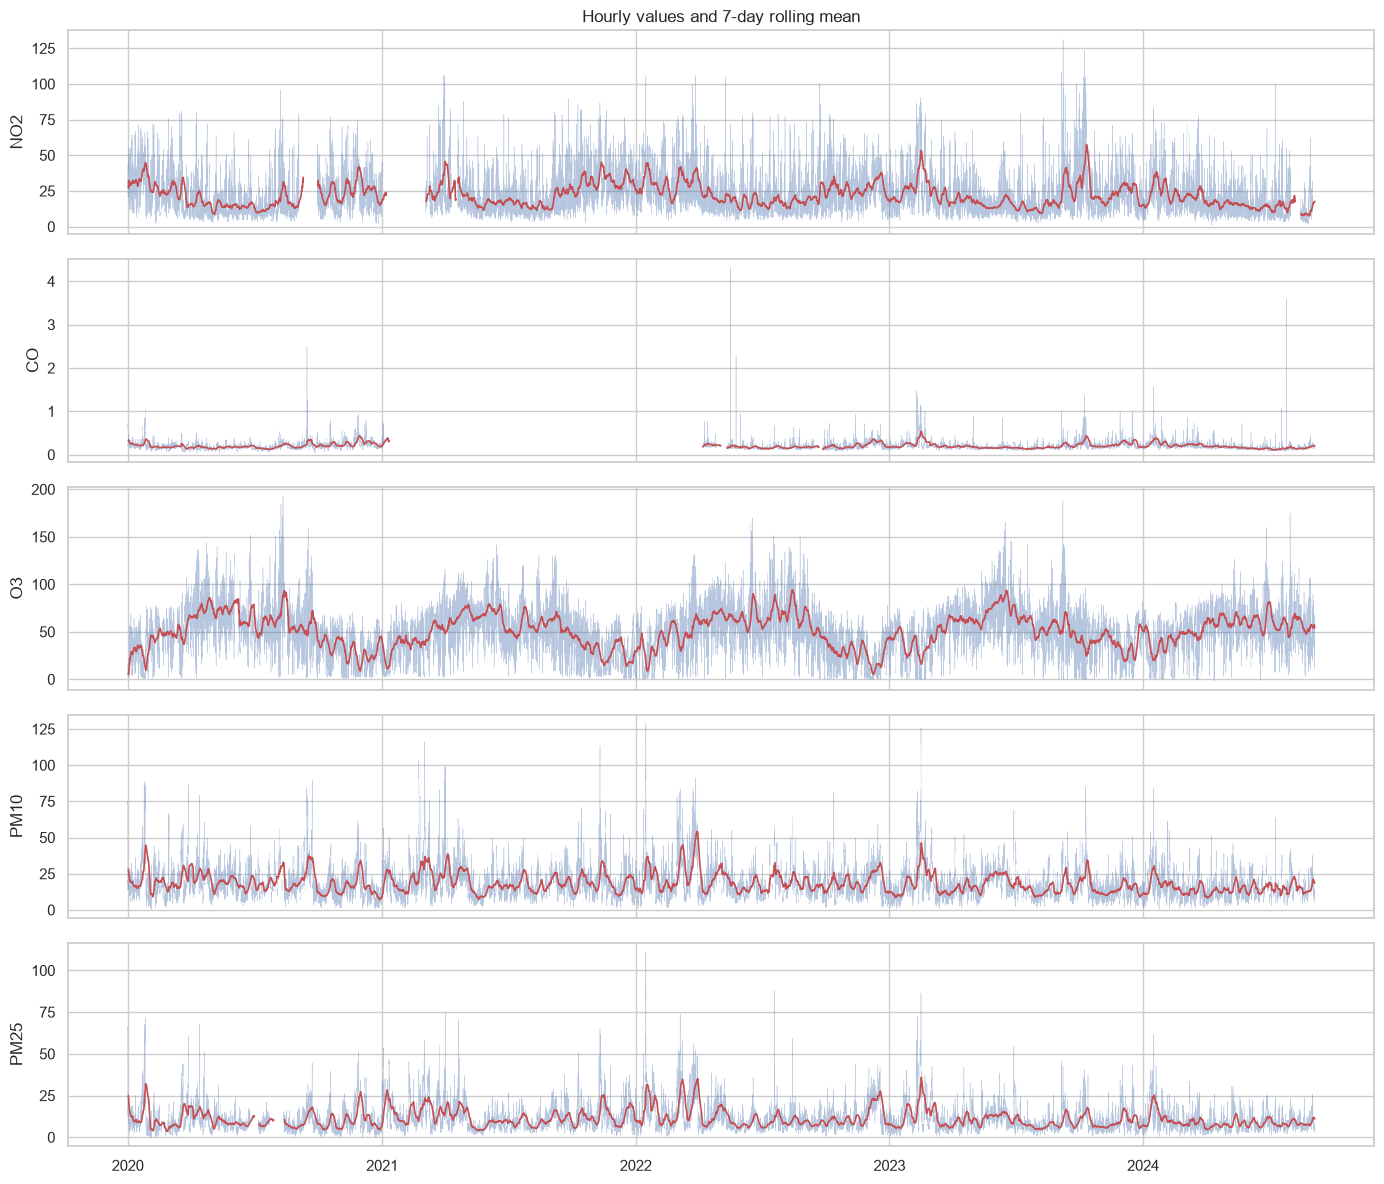

In [7]:
# Full series: hourly values (light) + 7-day rolling mean
fig, axes = plt.subplots(len(POLLUTANTS), 1, figsize=(14, 12), sharex=True)
for ax, c in zip(axes, POLLUTANTS):
    ax.plot(df.index, df[c], lw=0.3, alpha=0.4)
    ax.plot(df.index, df[c].rolling(168, min_periods=24).mean(), lw=1.2, c="C3")
    ax.set_ylabel(c.replace("valeur_", ""))
axes[0].set_title("Hourly values and 7-day rolling mean")
plt.tight_layout()
plt.show()

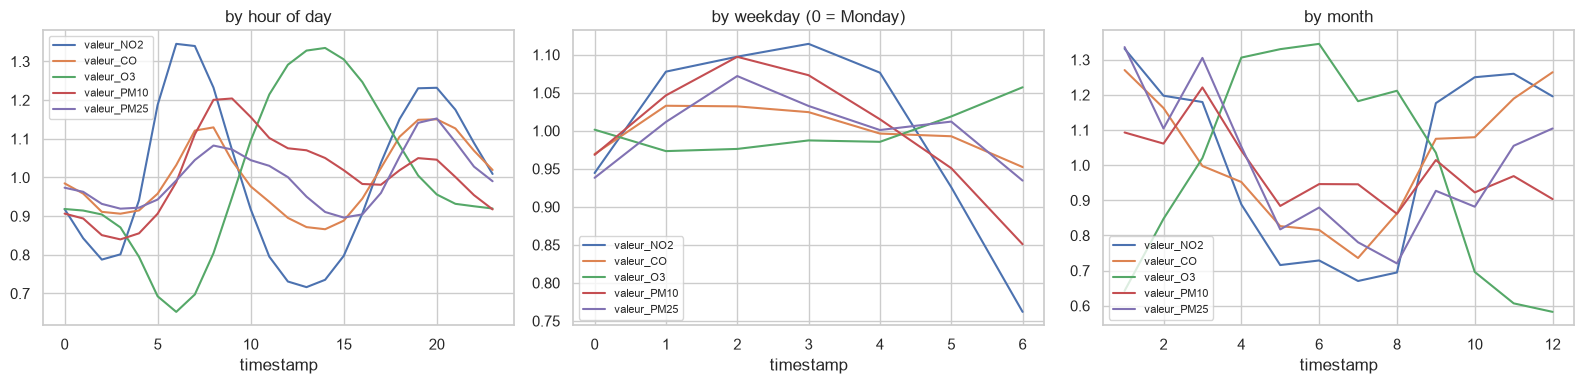

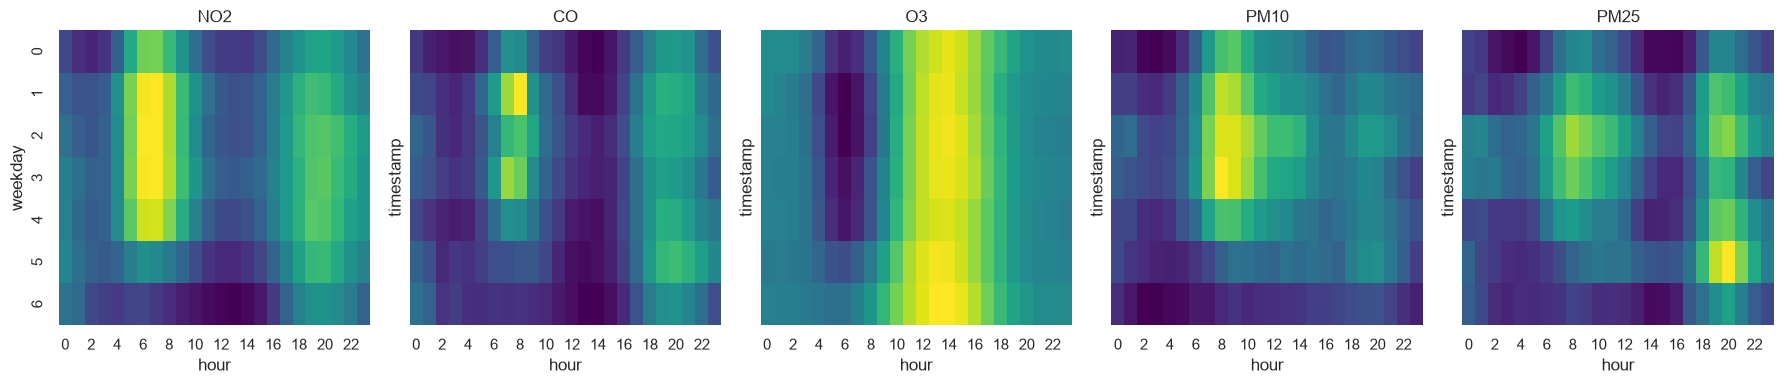

In [8]:
# Average profiles (each pollutant divided by its mean, so shapes are comparable)
norm = df / df.mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
norm.groupby(norm.index.hour).mean().plot(ax=axes[0], title="by hour of day")
norm.groupby(norm.index.dayofweek).mean().plot(ax=axes[1], title="by weekday (0 = Monday)")
norm.groupby(norm.index.month).mean().plot(ax=axes[2], title="by month")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Hour x weekday heatmap per pollutant
fig, axes = plt.subplots(1, len(POLLUTANTS), figsize=(18, 4), sharey=True)
for ax, c in zip(axes, POLLUTANTS):
    sns.heatmap(df[c].groupby([df.index.dayofweek, df.index.hour]).mean().unstack(), ax=ax, cbar=False, cmap="viridis")
    ax.set_title(c.replace("valeur_", ""))
    ax.set_xlabel("hour")
axes[0].set_ylabel("weekday")
plt.tight_layout()
plt.show()

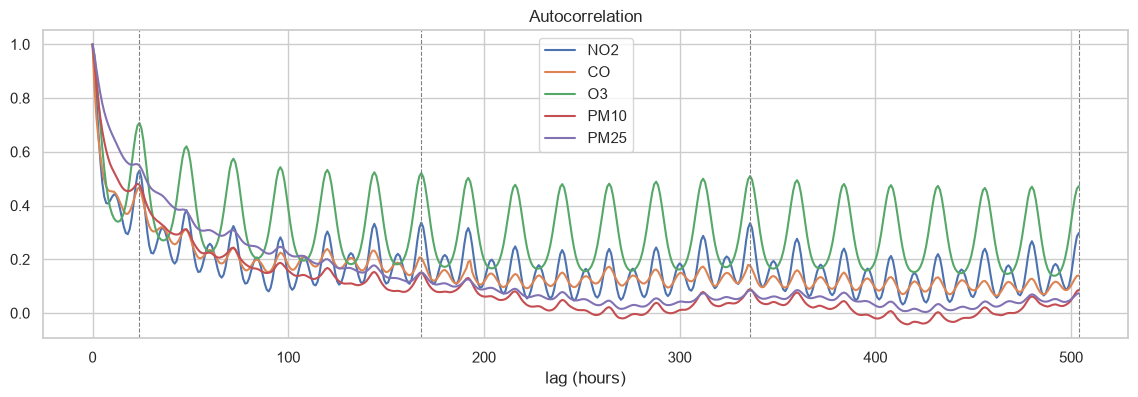

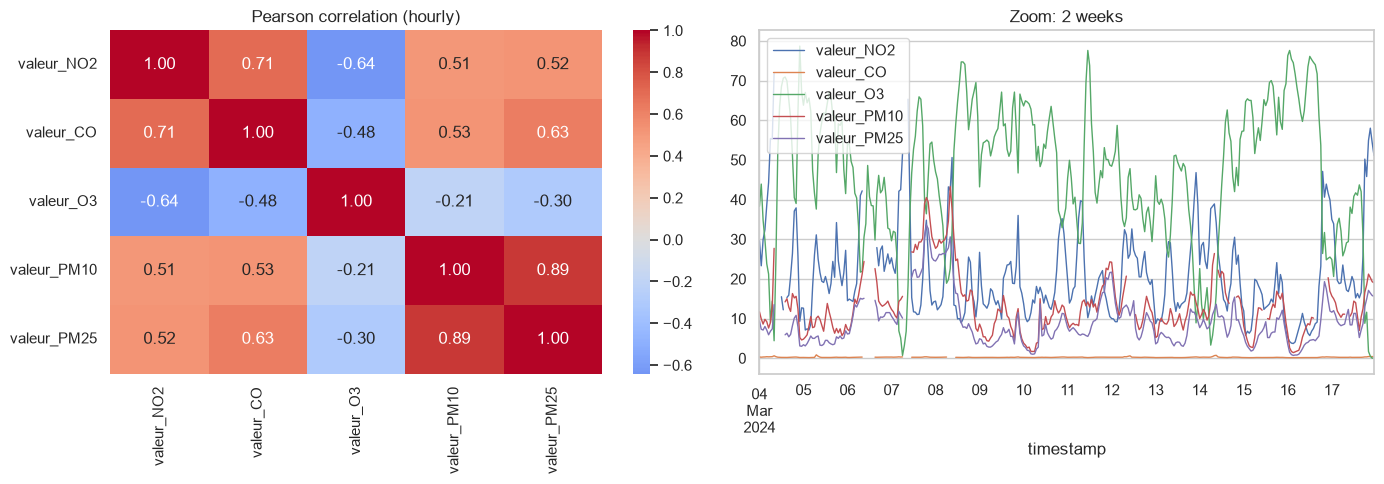

In [9]:
from statsmodels.tsa.stattools import acf

# Autocorrelation up to 3 weeks: peaks at 24h multiples and 168h reveal daily / weekly cycles
fig, ax = plt.subplots()
for c in POLLUTANTS:
    ax.plot(acf(df[c], nlags=HORIZON, missing="conservative"), label=c.replace("valeur_", ""))
for lag in (24, 168, 336, 504):
    ax.axvline(lag, ls="--", c="grey", lw=0.8)
ax.set_xlabel("lag (hours)")
ax.set_title("Autocorrelation")
ax.legend()
plt.show()

# Relationships between pollutants
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Pearson correlation (hourly)")
df.loc["2024-03-04":"2024-03-17"].plot(ax=axes[1], title="Zoom: 2 weeks", lw=1)
plt.tight_layout()
plt.show()

**Observations from the plots** (trends, daily / weekly patterns, peaks, relationships):

> *Your answer*

**Points to discuss:** Which patterns seem visible in the data: hourly, daily or weekly? Give evidence from your plots.

> *Your answer*

**Points to discuss:** How will you handle missing values? Explain why you must not interpolate using future validation or test data.

> *Your answer*

In [10]:
# TODO: missing-value handling (if any) — only using past information

# 2. Validation strategy and baselines

Before using a foundation model, build simple baselines. They are useful references and are often hard to beat on seasonal data.

**Work to complete:** Create a time-based validation split with a 504-hour forecast horizon. Make sure no future information enters the training data.

In [11]:
# Validation = last 504 hours of train. Everything a model sees must come from train_df only.
val_start = df.index[-HORIZON]
train_df = df.loc[df.index < val_start]
val = df.loc[df.index >= val_start]

assert len(val) == HORIZON and train_df.index.max() < val.index.min()
print(f"train_df: {train_df.index.min()} -> {train_df.index.max()} ({len(train_df)} h)")
print(f"val     : {val.index.min()} -> {val.index.max()} ({len(val)} h)")
print("missing observations in val:", val.isna().sum().to_dict())

train_df: 2020-01-01 00:00:00 -> 2024-08-13 22:00:00 (40487 h)
val     : 2024-08-13 23:00:00 -> 2024-09-03 22:00:00 (504 h)
missing observations in val: {'valeur_NO2': 110, 'valeur_CO': 6, 'valeur_O3': 0, 'valeur_PM10': 205, 'valeur_PM25': 13}


**Work to complete:** Implement at least two baselines: persistence and seasonal naive. For the seasonal naive model, test a 168-hour lag and justify it.

In [12]:
# TODO: persistence baseline -> record("persistence", y_pred)

In [13]:
# TODO: seasonal naive (lag 168) -> record("seasonal_naive_168", y_pred)

In [14]:
results_table()

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,average


**Points to discuss:** Why is a 168-hour lag useful for hourly urban pollution data?

> *Your answer*

**Points to discuss:** Why should you report MAE for each pollutant, not only the average MAE?

> *Your answer*

# 3. Time-series foundation models

Use a pretrained time-series foundation model in zero-shot mode. This means the model produces forecasts from historical context without being trained again on this Paris dataset.

**Points to discuss:** What is a time-series foundation model? How is it different from a model trained only on this dataset?

> *Your answer*

**Points to discuss:** What does zero-shot forecasting mean in this context?

> *Your answer*

**Points to discuss:** Why could forecasting all pollutants together help? Give one possible advantage and one possible risk.

> *Your answer*

**Points to discuss:** Classify the following as target, past-only covariate or known-future covariate: pollutant history, historical weather, hour of day and future weather observations.

| Variable | Role |
|---|---|
| Pollutant history | |
| Historical weather | |
| Hour of day | |
| Future weather observations | |

# 4. Zero-shot forecasting experiment

Run the experiment in Google Colab. Keep the setup simple and reproducible.

**Work to complete:** Run the foundation model in zero-shot mode. Record the model name, version, hardware and main settings.

In [15]:
from importlib.metadata import version

print("chronos-forecasting", version("chronos-forecasting"), "| torch", torch.__version__, "| python", platform.python_version())
print("hardware:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else DEVICE, "| colab:", IN_COLAB)

chronos-forecasting 2.3.2 | torch 2.14.1 | python 3.12.1
hardware: mps | colab: False


In [16]:
# TODO: load Chronos-2 + record model name and main settings (context length, quantiles, ...)

**Work to complete:** Prepare the data in the format expected by the model. Use only information available before the validation period.

In [17]:
# TODO

**Work to complete:** Generate forecasts for the full 504-hour horizon.

In [18]:
# TODO

**Work to complete:** Align predictions with the validation timestamps and compute MAE for each pollutant and on average.

In [19]:
# TODO: record("chronos2_...", y_pred)

**Points to discuss:** Why can the median forecast be a good choice when the metric is MAE?

> *Your answer*

# 5. Comparative experiments

Two simple comparisons, same validation period and metric. The goal is not to test many ideas, but to understand the effect of the modelling choice.

- **Independent vs joint forecasting:** one model per pollutant vs one joint model that predicts all pollutants together.
- **Foundation model vs neural network:** the foundation model vs a simple LSTM or RNN trained on the dataset.

## 5.1 Independent vs joint forecasting

In [20]:
# TODO: one model per pollutant -> record(...)

In [21]:
# TODO: joint model -> record(...)

## 5.2 Foundation model vs LSTM / RNN

In [22]:
# TODO: LSTM / RNN trained on train_df -> record("lstm", y_pred)

In [23]:
results_table()

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,average


**Points to discuss:** Which approach works best: one model per pollutant, one joint model, or the LSTM/RNN? Explain the result using the MAE per pollutant.

> *Your answer*

# 6. Results and discussion

**Work to complete:** Compare all models using MAE per pollutant and average MAE. Highlight cases where the average hides important differences.

In [24]:
results_table().astype(float).style.highlight_min(axis=0, color="lightgreen").format("{:.3f}")

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,average


> *Your answer*

**Work to complete:** Analyse whether performance changes between the beginning and the end of the 504-hour horizon.

In [25]:
# TODO

**Work to complete:** Plot observed vs predicted values. Comment on one clear success or failure.

In [26]:
# TODO: plot_forecast({"model": y_pred, ...}, "valeur_NO2")

> *Your answer*

**Points to discuss:** Which model performs best overall? Is it also best for every pollutant?

> *Your answer*

**Points to discuss:** Where does the foundation model fail compared with the seasonal naive baseline?

> *Your answer*

**Points to discuss:** List three limitations of your work: one about the data, one about the evaluation and one about the model.

- **Data:**
- **Evaluation:**
- **Model:**

# 7. Final forecast and submission

**Work to complete:** Select the final method using validation results only, then generate forecasts for the competition test period.

In [27]:
# TODO: refit / re-run the chosen method on the full train (df), forecast test["timestamp"] -> y_pred_test

**Work to complete:** Check that the final submission follows the required format and contains complete, correctly ordered predictions for all five pollutants.

In [28]:
# path = make_submission(y_pred_test)
# check_submission(path)

# References

- Ansari et al., *Chronos-2: From Univariate to Universal Forecasting*. Technical description of the model and its group-attention approach.
- Chronos-2 quick-start notebook
- Kaggle challenge description and data: https://www.kaggle.com/competitions/x-hec-ts-2025-predicting-air-quality-in-paris